In [1]:
import pandas as pd, numpy as np
df = pd.read_csv("data/Dataset.csv")
df = df.replace("Not Given", "Unknown")
df = df.drop_duplicates(subset=["title", "type", "release_year"]).reset_index(drop=True)
df["date_added"]   = pd.to_datetime(df["date_added"], format="mixed")
df["year_added"]   = df["date_added"].dt.year
df["month_added"]  = df["date_added"].dt.month
df["duration_num"] = df["duration"].str.extract(r"(\d+)").astype(int)
df["main_country"] = df["country"].str.split(",").str[0].str.strip()
df["genres"]       = df["listed_in"].str.split(", ")



=== Dataset Class Distribution ===
type
Movie      0.697
TV Show    0.303
Name: proportion, dtype: float64

Total records: 8786
Movie records: 6123
TV Show records: 2663

=== LEAKAGE DEMONSTRATION: WITH DURATION ===
                     test_accuracy  f1_TV_Show  cv_accuracy_5fold  cv_f1_5fold
model                                                                         
Logistic Regression          0.997       0.994              0.995        0.992
Decision Tree                0.998       0.996              0.998        0.996
Random Forest                0.998       0.996              0.998        0.997
Gradient Boosting            0.998       0.996              0.998        0.997

=== BASIC FEATURES: WITHOUT DURATION OR GENRES ===
                     test_accuracy  f1_TV_Show  cv_accuracy_5fold  cv_f1_5fold
model                                                                         
Logistic Regression          0.716       0.644              0.707        0.641
Decision Tree        

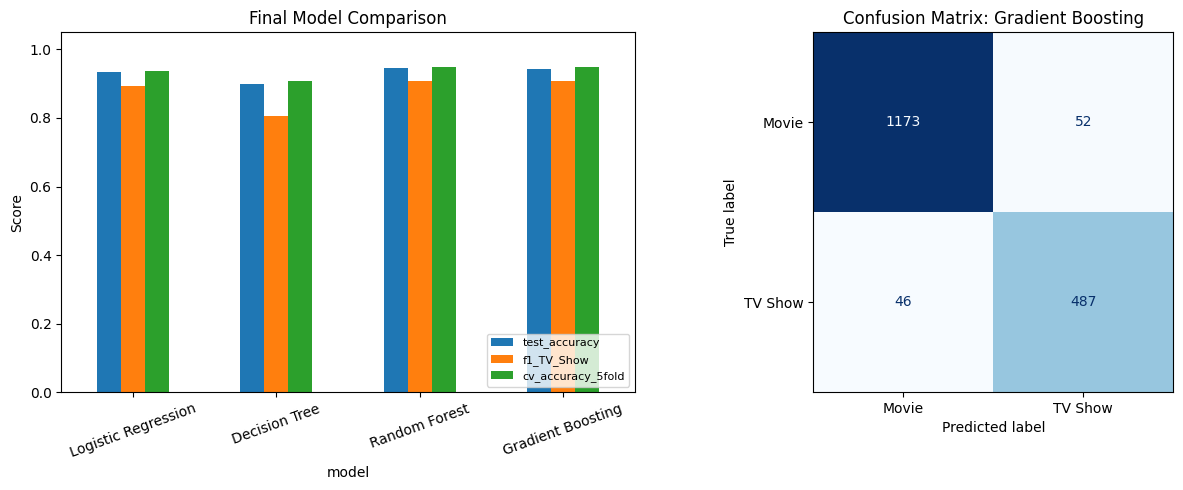

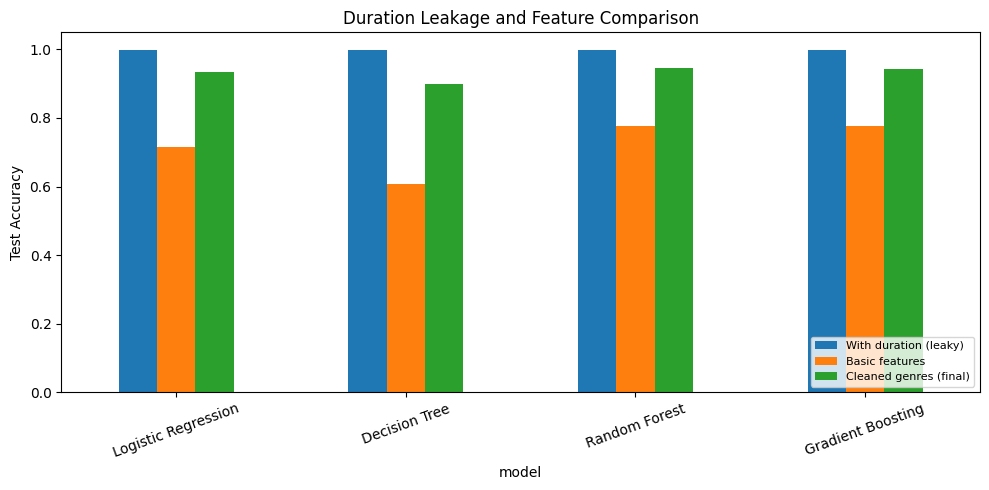


=== Files Saved ===
Model comparison: results/task2_model_comparison.csv
Classification report: results/task2_classification_report.txt
Summary: results/task2_summary.txt
Charts: figures/task2_model_comparison.png
        figures/task2_leakage_check.png

Completed in 10.9 seconds.


In [ ]:

# Predict whether a Netflix title is a Movie or TV Show.

import os
import re
import time
import warnings
from pathlib import Path

os.environ["PYTHONWARNINGS"] = "ignore::RuntimeWarning"
warnings.filterwarnings("ignore", category=RuntimeWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MultiLabelBinarizer,
    OneHotEncoder,
    StandardScaler
)
from sklearn.tree import DecisionTreeClassifier


# ---------- Configuration ----------

SEED = 42
SHOW_PLOTS = True

START = time.time()

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)


# ---------- Step 1: Load and clean dataset ----------

df = pd.read_csv("data/Dataset.csv")

required_columns = [
    "title", "type", "release_year", "date_added",
    "duration", "country", "rating", "listed_in"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Dataset is missing required columns: {missing_columns}"
    )

# Clean text columns without applying string methods to numeric columns.
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

df = df.replace({
    "Not Given": "Unknown",
    "": "Unknown"
})

# Remove records without a usable target.
df = df.dropna(subset=["type"])
df = df[df["type"].isin(["Movie", "TV Show"])].copy()

# Remove duplicate records.
df = df.drop_duplicates(
    subset=["title", "type", "release_year"]
).reset_index(drop=True)

# Replace remaining missing text values.
for col in ["title", "date_added", "duration",
            "country", "rating", "listed_in"]:
    df[col] = df[col].fillna("Unknown").astype(str)

# Date-related features.
dates = pd.to_datetime(
    df["date_added"],
    format="%m/%d/%Y",
    errors="coerce"
)

df["year_added"] = dates.dt.year
df["month_added"] = dates.dt.month

# Duration is included only in the leakage demonstration.
df["duration_num"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Extract the first listed country.
df["main_country"] = (
    df["country"]
    .str.split(",")
    .str[0]
    .str.strip()
    .replace("", "Unknown")
)

# Target: 0 = Movie, 1 = TV Show.
y = (df["type"] == "TV Show").astype(int)

print("=== Dataset Class Distribution ===")
print(y.map({0: "Movie", 1: "TV Show"}).value_counts(normalize=True).round(3))

print(f"\nTotal records: {len(df)}")
print(f"Movie records: {(y == 0).sum()}")
print(f"TV Show records: {(y == 1).sum()}")


# ---------- Step 2: Clean genre features ----------

def core_genres(listed_in):
    """
    Remove direct content-type words from genre labels.
    Example: 'TV Dramas' becomes 'Dramas'.
    """
    cleaned = []

    for genre in str(listed_in).split(","):
        genre = re.sub(
            r"\b(TV|Shows|Movies)\b",
            "",
            genre,
            flags=re.IGNORECASE
        )

        genre = re.sub(r"\s+", " ", genre).strip(" ,")

        if genre and genre.lower() != "unknown":
            cleaned.append(genre)

    return sorted(set(cleaned))


genre_lists = df["listed_in"].apply(core_genres)

# Multi-label binary encoding: one column per cleaned genre.
mlb = MultiLabelBinarizer()

genre_matrix = mlb.fit_transform(genre_lists)

genre_cols = [
    f"genre_{i}" for i in range(genre_matrix.shape[1])
]

genre_df = pd.DataFrame(
    genre_matrix,
    columns=genre_cols,
    index=df.index
)

df = pd.concat([df, genre_df], axis=1)


# ---------- Step 3: Define classifiers and preprocessing ----------

CAT_COLS = ["rating", "main_country"]

NUM_COLS = [
    "release_year",
    "year_added",
    "month_added"
]

MODELS = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        n_jobs=1,
        random_state=SEED
    ),

    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=SEED
    )
}

CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


def make_preprocessor(features):
    """Build preprocessing steps for the selected features."""

    cats = [c for c in CAT_COLS if c in features]

    nums = [
        c for c in NUM_COLS + ["duration_num"]
        if c in features
    ]

    transformers = []

    if cats:
        categorical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=20,
                sparse_output=False
            ))
        ])

        transformers.append(
            ("cat", categorical_pipeline, cats)
        )

    if nums:
        numerical_pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        transformers.append(
            ("num", numerical_pipeline, nums)
        )

    return ColumnTransformer(
        transformers,
        remainder="passthrough"
    )


# ---------- Step 4: Train and evaluate models ----------

def run(features, experiment_name):
    """
    Evaluate classifiers using 5-fold CV and a held-out test set.
    Select the winner later using cross-validation F1.
    """

    X = df[features].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=SEED
    )

    rows = []
    fitted_models = {}

    for name, model in MODELS.items():

        pipeline = Pipeline([
            ("pre", make_preprocessor(features)),
            ("model", model)
        ])

        # Cross-validation evaluates both accuracy and TV Show F1.
        cv_results = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=CV,
            scoring={
                "accuracy": "accuracy",
                "f1": "f1"
            },
            n_jobs=-1,
            error_score="raise"
        )

        # Fit using training data only.
        pipeline.fit(X_train, y_train)

        predictions = pipeline.predict(X_test)

        rows.append({
            "model": name,
            "test_accuracy": accuracy_score(
                y_test, predictions
            ),
            "f1_TV_Show": f1_score(
                y_test, predictions, zero_division=0
            ),
            "cv_accuracy_5fold": cv_results[
                "test_accuracy"
            ].mean(),
            "cv_f1_5fold": cv_results[
                "test_f1"
            ].mean()
        })

        fitted_models[name] = pipeline

    results_table = (
        pd.DataFrame(rows)
        .set_index("model")
        .round(3)
    )

    print(f"\n=== {experiment_name} ===")
    print(results_table.to_string())

    return (
        results_table,
        fitted_models,
        X_test,
        y_test
    )


# ---------- Step 5: Demonstrate duration leakage ----------

leaky_table, _, _, _ = run(
    CAT_COLS + NUM_COLS + ["duration_num"],
    "LEAKAGE DEMONSTRATION: WITH DURATION"
)


# ---------- Step 6: Evaluate basic features ----------

basic_table, _, _, _ = run(
    CAT_COLS + NUM_COLS,
    "BASIC FEATURES: WITHOUT DURATION OR GENRES"
)


# ---------- Step 7: Final model comparison ----------

final_features = CAT_COLS + NUM_COLS + genre_cols

table, fitted_models, X_test, y_test = run(
    final_features,
    "FINAL MODEL: CLEANED GENRES, NO DURATION"
)

table.to_csv("results/task2_model_comparison.csv")


# ---------- Step 8: Select the best model using CV F1 ----------

best_model_name = table["cv_f1_5fold"].idxmax()
best_model = fitted_models[best_model_name]

print(
    "\nBest model by 5-fold cross-validation TV Show F1:",
    best_model_name
)

print(
    "Cross-validation F1:",
    table.loc[best_model_name, "cv_f1_5fold"]
)

print(
    "Held-out test accuracy:",
    table.loc[best_model_name, "test_accuracy"]
)


# ---------- Step 9: Classification report ----------

test_predictions = best_model.predict(X_test)

report = classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Movie", "TV Show"],
    zero_division=0
)

print("\n=== Final Classification Report ===")
print(report)

Path(
    "results/task2_classification_report.txt"
).write_text(report, encoding="utf-8")


# ---------- Step 10: Plot model comparison ----------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

table[
    ["test_accuracy", "f1_TV_Show", "cv_accuracy_5fold"]
].plot.bar(
    ax=axes[0],
    rot=20
)

axes[0].set_title("Final Model Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].legend(
    loc="lower right",
    fontsize=8
)

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    labels=[0, 1],
    display_labels=["Movie", "TV Show"],
    ax=axes[1],
    cmap="Blues",
    colorbar=False
)

axes[1].set_title(
    f"Confusion Matrix: {best_model_name}"
)

fig.tight_layout()
fig.savefig(
    "figures/task2_model_comparison.png",
    dpi=150,
    bbox_inches="tight"
)


# ---------- Step 11: Plot leakage comparison ----------

leakage_comparison = pd.DataFrame({
    "With duration (leaky)": leaky_table["test_accuracy"],
    "Basic features": basic_table["test_accuracy"],
    "Cleaned genres (final)": table["test_accuracy"]
})

ax = leakage_comparison.plot.bar(
    figsize=(10, 5),
    rot=20
)

ax.set_title("Duration Leakage and Feature Comparison")
ax.set_ylabel("Test Accuracy")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig(
    "figures/task2_leakage_check.png",
    dpi=150,
    bbox_inches="tight"
)

if SHOW_PLOTS:
    plt.show()
else:
    plt.close("all")


# ---------- Step 12: Save a summary ----------

summary = f"""
Netflix Content Type Prediction
================================

Task:
Predict Movie vs TV Show.

Final Method:
Supervised classification using cleaned metadata and genre features.

Models:
Logistic Regression
Decision Tree
Random Forest
Gradient Boosting

Final Features:
Rating, main country, release year, year added,
month added, and cleaned genres.

Duration:
Excluded from the final model because it directly reveals
information about content type.

Model Selection:
Highest mean 5-fold cross-validation F1-score for TV Show.

Selected Model: {best_model_name}

Cross-validation F1:
{table.loc[best_model_name, 'cv_f1_5fold']:.3f}

Held-out Test Accuracy:
{table.loc[best_model_name, 'test_accuracy']:.3f}

Evaluation:
Test accuracy, TV Show F1-score, cross-validation metrics,
classification report, and confusion matrix.

Note:
These are classification metrics, not recommendation metrics.
"""

Path(
    "results/task2_summary.txt"
).write_text(summary.strip(), encoding="utf-8")

print("\n=== Files Saved ===")
print("Model comparison: results/task2_model_comparison.csv")
print("Classification report: results/task2_classification_report.txt")
print("Summary: results/task2_summary.txt")
print("Charts: figures/task2_model_comparison.png")
print("        figures/task2_leakage_check.png")

print(f"\nCompleted in {time.time() - START:.1f} seconds.")
